In [28]:
import pandas as pd

df = pd.read_csv('HousePrices_dataset copy.csv')
df.head()


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,02-05-2014 00:00,313000.0,3,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,02-05-2014 00:00,2384000.0,5,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,02-05-2014 00:00,342000.0,3,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,02-05-2014 00:00,420000.0,3,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,02-05-2014 00:00,550000.0,4,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [29]:
# Shape (rows, columns) and size (total number of values)
print('Shape:', df.shape)
print('Size:', df.size)

Shape: (4600, 18)
Size: 82800


In [30]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   int64  
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(3), int6

In [31]:
# Null values in each column
print(df.isnull().sum())
print('Total null values:', df.isnull().sum().sum())

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64
Total null values: 0


In [32]:
# Summary statistics
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


Insights: The dataset has 4,600 rows and 18 columns (size = 82,800 values). There are no null values in any column, so no missing-value handling is needed. Prices range from $0 to about $26.6 million, which already suggests invalid prices and extreme outliers to look at.

In [33]:
print(f"Average house price (original data): ${df['price'].mean():,.2f}")

Average house price (original data): $551,962.99


In [34]:
# Check for duplicate rows and for prices of 0
print('Duplicate rows:', df.duplicated().sum())
print('Houses with price = 0:', (df['price'] == 0).sum())
print('Houses with 0 bedrooms:', (df['bedrooms'] == 0).sum())

Duplicate rows: 0
Houses with price = 0: 49
Houses with 0 bedrooms: 2


Insights: There are no duplicate rows, but 49 houses have a price of $0. A house cannot sell for $0, so these are invalid records that would pull the average down. I remove them. (Two houses also list 0 bedrooms; I keep them because their prices are valid.)

In [35]:
# Remove houses with price = 0 (invalid prices, not real sales)
df = df[df['price'] > 0].copy()

print('Shape after cleaning:', df.shape)
print(f"Average house price (cleaned data): ${df['price'].mean():,.2f}")

Shape after cleaning: (4551, 18)
Average house price (cleaned data): $557,905.90


Insight: The average price is $551,962.99 on the original data and $557,905.90 after removing the 49 invalid $0 prices. The cleaned value is used for the rest of the analysis (4,551 houses).

In [36]:
avg_price = df['price'].mean()
print(f'Average house price: ${avg_price:,.2f}')

Average house price: $557,905.90


In [37]:
print('Most common bedrooms:', df['bedrooms'].mode()[0])
print('Most common bathrooms:', df['bathrooms'].mode()[0])

Most common bedrooms: 3
Most common bathrooms: 2.5


In [38]:
numeric_cols = df.select_dtypes(include='number')
corr_with_price = numeric_cols.corr()['price'].drop('price').sort_values(ascending=False)
corr_with_price

sqft_living      0.445494
sqft_above       0.380661
bathrooms        0.341126
view             0.242587
sqft_basement    0.217782
bedrooms         0.210228
floors           0.152758
waterfront       0.150083
sqft_lot         0.051347
condition        0.038892
yr_built         0.021757
yr_renovated    -0.029034
Name: price, dtype: float64

In [39]:
# The three features named in the assignment
df[['price', 'sqft_living', 'waterfront', 'view']].corr()['price']

price          1.000000
sqft_living    0.445494
waterfront     0.150083
view           0.242587
Name: price, dtype: float64

Insight: Every numeric feature has a positive correlation with price except `yr_renovated`, which is slightly negative. `sqft_living` (0.45) is the strongest, followed by `sqft_above` (0.38) and `bathrooms` (0.34). `view` (0.24) and `waterfront` (0.15) are weaker but positive. All correlations are moderate or weak, so no single feature explains price on its own. Location and extreme outliers also play a role.

In [40]:
waterfront_avg = df.groupby('waterfront')['price'].mean()
waterfront_avg.index = ['Non-waterfront (0)', 'Waterfront (1)']
waterfront_avg

Non-waterfront (0)    5.510122e+05
Waterfront (1)        1.596783e+06
Name: price, dtype: float64

Insight: Waterfront houses average about $1,596,783 versus about $551,012 for non-waterfront houses, nearly 3 times higher. Only 30 waterfront houses are in the data, so this is a small but very high-value segment.

In [41]:
df.groupby('floors')['price'].mean()

floors
1.0    462168.231569
1.5    585283.733253
2.0    655221.246092
2.5    983863.390244
3.0    570615.521432
3.5    829250.000000
Name: price, dtype: float64


Insight: Average price generally rises with the number of floors: 1 floor is the lowest (about $462,168), 2 floors about $655,221, and 2.5 floors is the highest (about $983,863). The 3.0 and 3.5 floor averages break the trend, but there are very few such houses (127 and only 2), so they are less reliable.

In [42]:
df.groupby('condition')['price'].mean()

condition
1    306633.333333
2    334837.419355
3    554742.409552
4    539682.069598
5    652030.529840
Name: price, dtype: float64

Insight- Houses in poor condition sell for much less: condition 1 averages about $306,633 and condition 2 about $334,837. Condition 3 and 4 are similar (about $554,742 and $539,682), and **condition 5 is the highest at about $652,031**. Most houses are condition 3 or 4, so only a few are in poor shape.

<Axes: title={'center': 'Distribution of House Prices'}, ylabel='Frequency'>

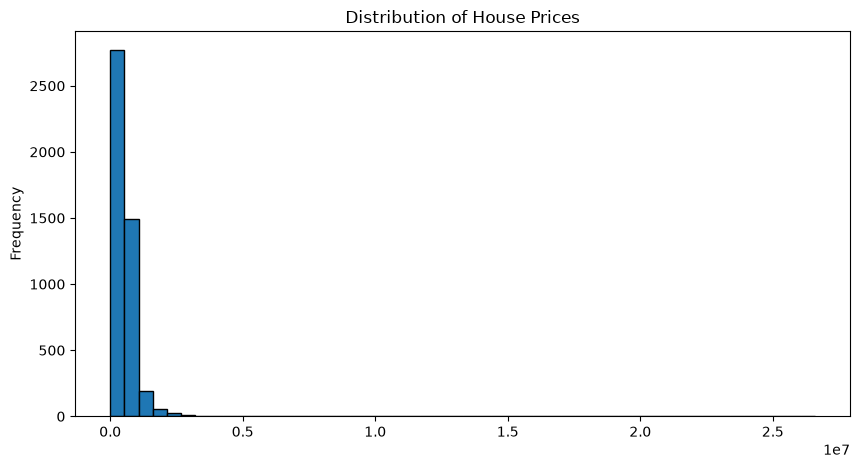

In [43]:
df['price'].plot(kind='hist', bins=50, figsize=(10, 5), title='Distribution of House Prices', edgecolor='black')

Insight: The price distribution is right-skewed: most houses are priced under about $1 million, and a few very expensive houses (up to $26.6 million) stretch the tail. Because of this, the average ($557,906) is higher than the median ($465,000).

<Axes: title={'center': 'Price vs. Living Area (sqft)'}, xlabel='sqft_living', ylabel='price'>

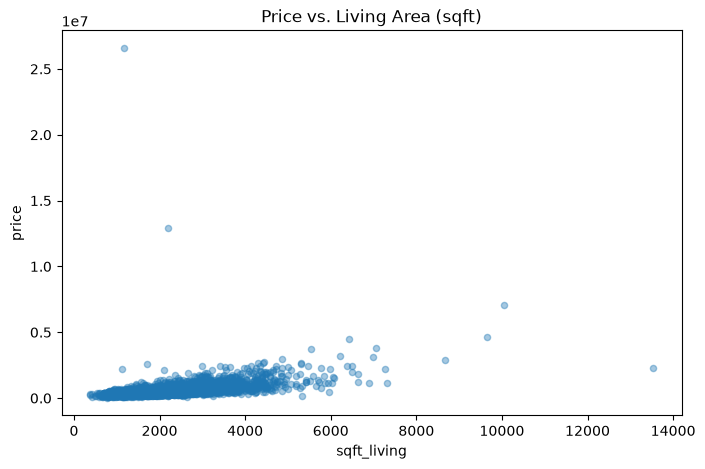

In [44]:
df.plot(kind='scatter', x='sqft_living', y='price', alpha=0.4, figsize=(8, 5), title='Price vs. Living Area (sqft)')

<Axes: title={'center': 'Price vs. Bedrooms'}, xlabel='bedrooms', ylabel='price'>

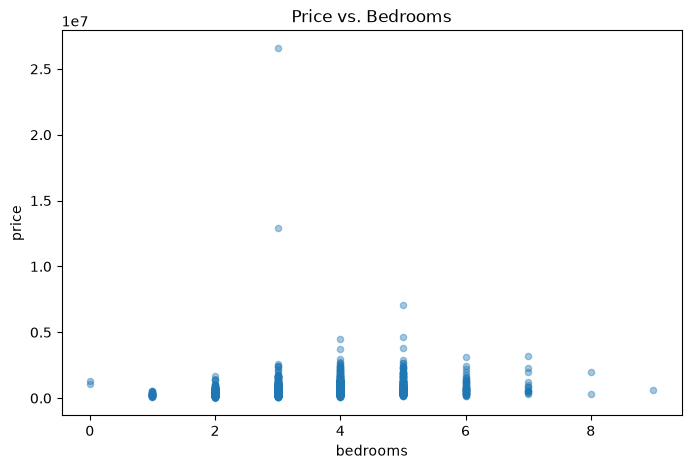

In [45]:
df.plot(kind='scatter', x='bedrooms', y='price', alpha=0.4, figsize=(8, 5), title='Price vs. Bedrooms')

<Axes: title={'center': 'Price vs. Bathrooms'}, xlabel='bathrooms', ylabel='price'>

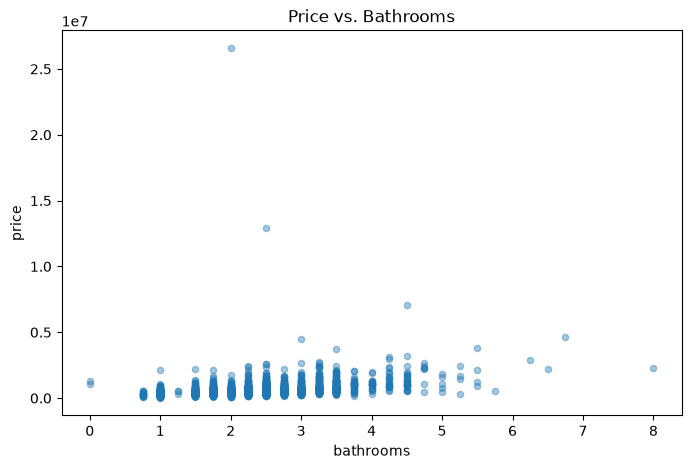

In [46]:
df.plot(kind='scatter', x='bathrooms', y='price', alpha=0.4, figsize=(8, 5), title='Price vs. Bathrooms')

<Axes: title={'center': 'Price vs. View Rating'}, xlabel='view', ylabel='price'>

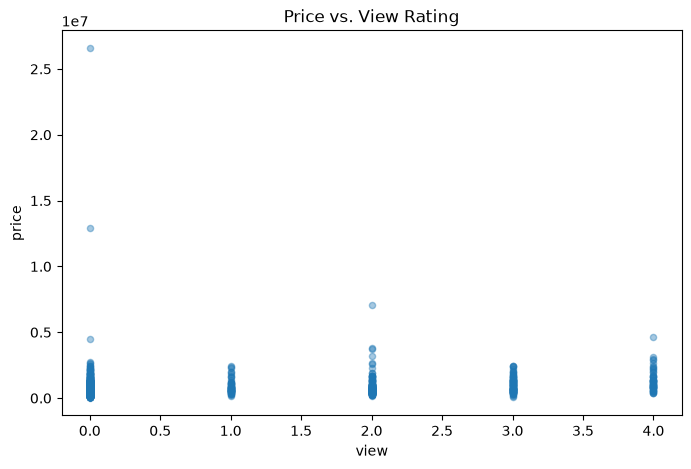

In [47]:
df.plot(kind='scatter', x='view', y='price', alpha=0.4, figsize=(8, 5), title='Price vs. View Rating')

<Axes: title={'center': 'Price vs. Waterfront (0 = No, 1 = Yes)'}, xlabel='waterfront', ylabel='price'>

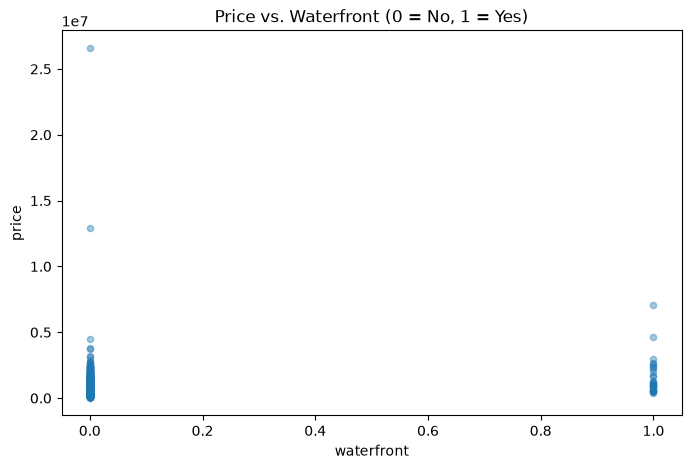

In [48]:
df.plot(kind='scatter', x='waterfront', y='price', alpha=0.4, figsize=(8, 5), title='Price vs. Waterfront (0 = No, 1 = Yes)')


Insight: `sqft_living` shows a clear upward trend, so larger homes tend to cost more. Bedrooms, bathrooms and view show a weaker upward pattern with wide price spread in each group. For waterfront, the few waterfront houses (value 1) tend to sit at higher prices.

<Axes: title={'center': 'Number of Houses by City'}, xlabel='city'>

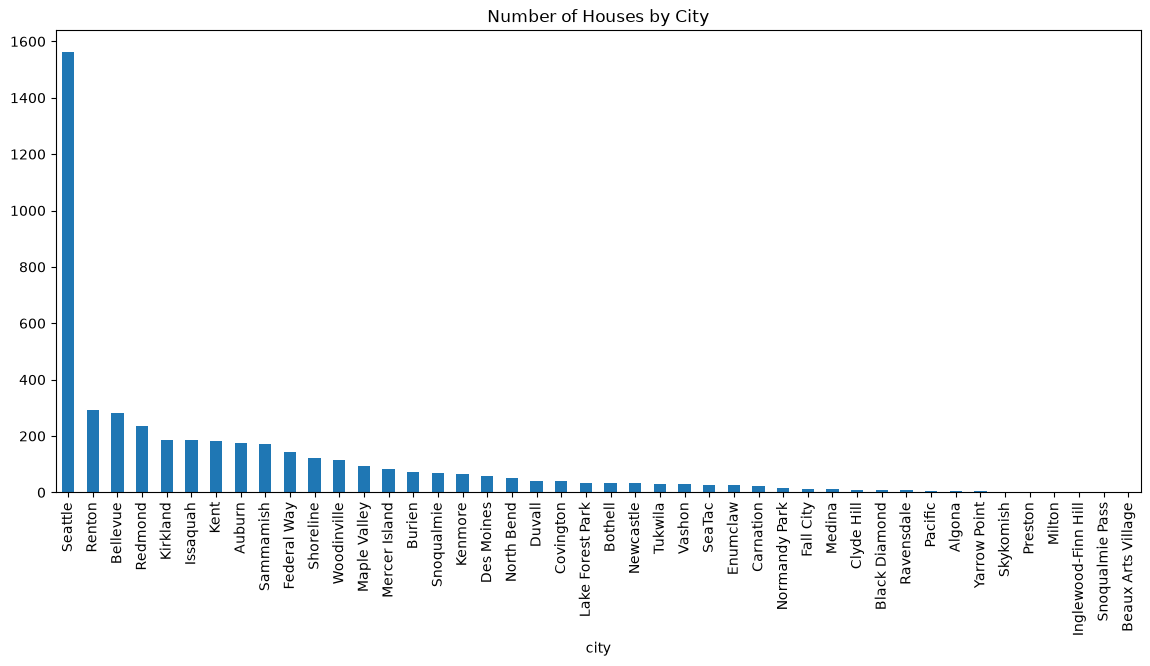

In [49]:
df['city'].value_counts().plot(kind='bar', figsize=(14, 6), title='Number of Houses by City')

Insight: Seattle: has by far the most listings (1,561 of 4,551 houses), followed by Renton (291), Bellevue (281), Redmond (235) and Kirkland (187). The data covers 44 cities, but most have only a small number of houses.

## Summary of Key Findings and Growth Opportunities

**Key findings**
- The average house price is about $557,906 (after removing 49 invalid $0 prices).
- The typical home has 3 bedrooms and 2.5 bathrooms.
- Living area (sqft_living) has the strongest correlation with price (0.45).
- Waterfront houses average about 3 times the price of non-waterfront houses.
- Price tends to rise with more floors, and houses in the best condition (5) sell for the most.
- Seattle has the most listings by a wide margin.

**Growth opportunities**
- Focus on larger, 3-4 bedroom homes, which are the most common and have the strongest link to higher prices.
- Build a premium waterfront and high-view listings segment, since these sell at much higher prices.
- Expand in Seattle and nearby cities (Bellevue, Redmond, Kirkland), where activity is highest.
- Help owners with lower-condition homes improve them, since condition 1-2 homes sell far below the rest.